# Initial environment setup and data exploration

In [2]:
import numpy as np
import matplotlib.pyplot as plt
PATH = r"..\data\preprocessed.npy"
dataset = np.load(PATH, allow_pickle=True) # Dataset from the APOLLO (2023) paper, preprocessed and saved as a NumPy array.

In [3]:
print("Shape:", dataset.shape)
print("Data type:", dataset.dtype)
print("Dimensions:", dataset.ndim)
print("Number of elements:", dataset.size)
print("Memory:", dataset.nbytes, "bytes")
print(dataset[0]["data"][0])

Shape: (59,)
Data type: object
Dimensions: 1
Number of elements: 59
Memory: 472 bytes
[[1.12586081e-02 0.00000000e+00 0.00000000e+00 ... 1.44051225e-03
  9.64099361e-05 4.96001031e-04]
 [2.41162764e-03 4.89834832e-03 6.00873493e-03 ... 0.00000000e+00
  1.45184602e-02 1.17679116e-02]
 [2.72575047e-03 0.00000000e+00 2.16562918e-04 ... 1.36039162e-02
  4.84496678e-03 3.44093923e-03]
 ...
 [1.13009690e-03 3.13478542e-03 4.34356679e-03 ... 2.00119337e-03
  7.99264127e-03 5.13989776e-03]
 [2.84740690e-03 4.11731089e-03 5.85303577e-03 ... 7.19129439e-03
  5.54758333e-03 2.69111022e-03]
 [2.66281933e-03 3.54517019e-03 1.92315271e-03 ... 1.40930957e-03
  2.87646852e-03 5.78533615e-03]]


In [4]:
item = dataset[0]

for key, value in item.items():
    if isinstance(value, np.ndarray):
        print(f"{key}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"{key}: type={type(value).__name__}, value={value}")

data: shape=(121, 51, 1167), dtype=float64
name: type=str, value=HF-305_v4b_1_1.h5_6
class_id: type=int, value=2
patient_id: type=int, value=305
tsne: shape=(6171, 2), dtype=float32
pca: shape=(6171, 2), dtype=float64


In [5]:
# Count the number of unique patient IDs in the dataset
from collections import Counter

id_counts = Counter(id["patient_id"] for id in dataset)
print(id_counts)
type_counts = Counter(type["class_id"] for type in dataset)
print(type_counts)
name_counts = Counter(name["name"] for name in dataset)
print(name_counts)

Counter({2849: 4, 2102: 3, 2104: 3, 682: 2, 894: 2, 988: 2, 1002: 2, 2493: 2, 2619: 2, 305: 1, 442: 1, 448: 1, 592: 1, 615: 1, 868: 1, 901: 1, 960: 1, 1010: 1, 1016: 1, 1043: 1, 1086: 1, 1293: 1, 1295: 1, 1334: 1, 1825: 1, 1887: 1, 2070: 1, 2106: 1, 2355: 1, 2454: 1, 2485: 1, 2534: 1, 2544: 1, 2548: 1, 2600: 1, 2608: 1, 2614: 1, 2666: 1, 2715: 1, 2776: 1, 2802: 1, 2852: 1, 2876: 1, 2898: 1, 3271: 1, 3337: 1})
Counter({5: 15, 4: 13, 2: 12, 3: 9, 1: 5, 6: 5})
Counter({'HF-305_v4b_1_1.h5_6': 1, 'HF-442_V4BB_1.h5_12': 1, 'HF-448_V5B_1.h5_3': 1, 'HF-592_V3T_1.h5_4': 1, 'HF-615_V5BB_1.h5_9': 1, 'HF-682_V3AT_1.h5_9': 1, 'HF-682_V3BB_1.h5_10': 1, 'HF-868_1_2.h5_4': 1, 'HF-894_9_1.h5_11': 1, 'HF-894_V1BB_1.h5_12': 1, 'HF-901_V2T_2.h5_10': 1, 'HF-960_VIAT_2.h5_11': 1, 'HF-988_V1-T_1.h5_13': 1, 'HF-988_V1B_1.h5_14': 1, 'HF-1002_V1AT_1.h5_0': 1, 'HF-1002_V2AT_1.h5_1': 1, 'HF-1010_V1T_1.h5_0': 1, 'HF-1016_IAT_2.h5_1': 1, 'HF-1043_V1AM_1.h5_0': 1, 'HF-1086_#1_1.h5_1': 1, 'HF-1293_13_1.h5_0': 1, 'HF-

In [6]:
print(len(id_counts), "unique patient IDs")

46 unique patient IDs


In [20]:
print(dataset[0]["data"].shape)
print(dataset[0]["name"])
print(dataset[0]["class_id"])
print(dataset[0]["patient_id"])

(121, 51, 1167)
HF-305_v4b_1_1.h5_6
2
305


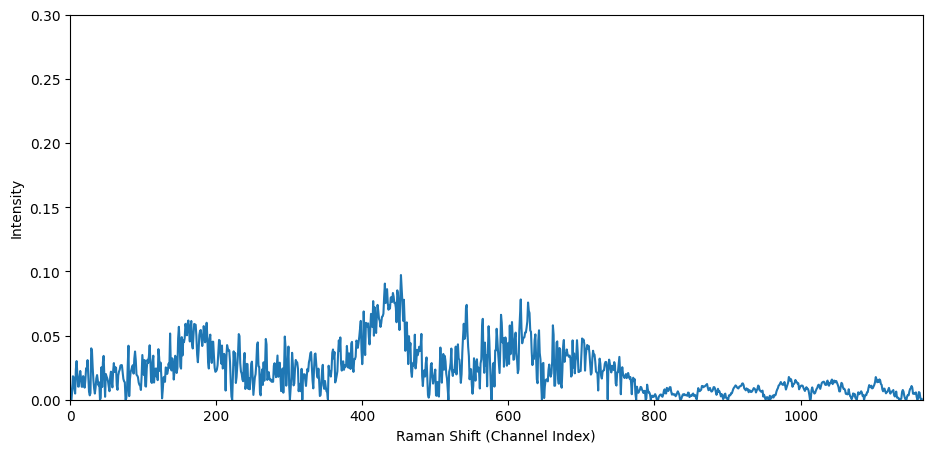

In [23]:
spectra1 = dataset[0]["data"][0][0]
x = np.arange(spectra1.shape[0])
fig, ax = plt.subplots(figsize=(11, 5))
plt.xlim(0,1167)
plt.ylim(0, 0.3)
plt.xlabel("Raman Shift (Channel Index)")
plt.ylabel("Intensity")
plt.plot(x, spectra1)

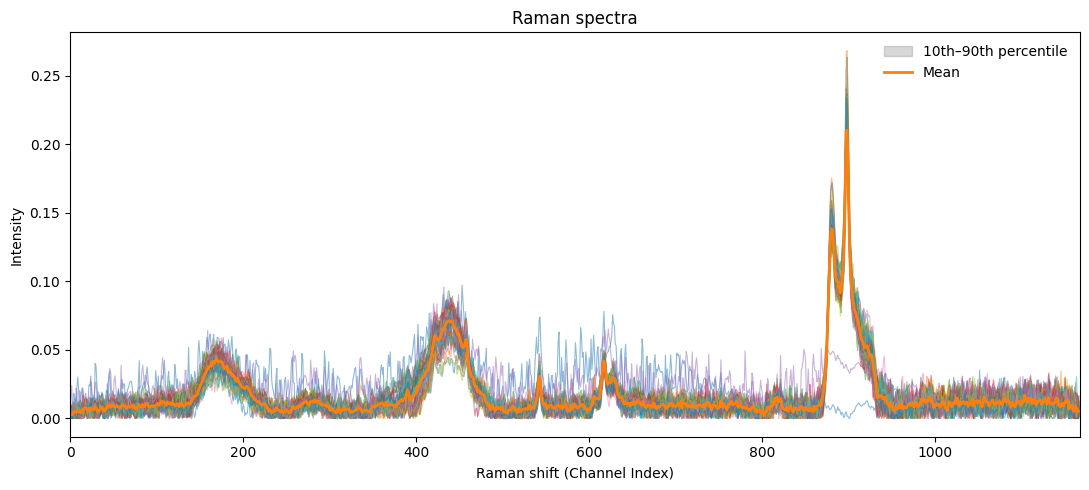

In [25]:
spectra = dataset[0]["data"][0]
x = np.arange(spectra.shape[1])
mean = spectra.mean(axis=0)
low, high = np.percentile(spectra, [10, 90], axis=0)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(x, spectra.T, alpha=0.5, lw=0.8)
ax.fill_between(x, low, high, color="gray", alpha=0.3, label="10th–90th percentile")
ax.plot(x, mean, lw=2, label="Mean")

ax.set(title="Raman spectra", xlabel="Raman shift (Channel Index)", ylabel="Intensity")

ax.legend(frameon=False)
plt.xlim(0,1167)
plt.tight_layout()
plt.show()

In [46]:
for i, item in enumerate(dataset[:3]):
    print(f"Entry {i}:")
    for key, value in item.items():
        if isinstance(value, np.ndarray):
            print(f"  {key}: array, shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"  {key}: {value!r}")

Entry 0:
  data: array, shape=(121, 51, 1167), dtype=float64
  name: 'HF-305_v4b_1_1.h5_6'
  class_id: 2
  patient_id: 305
  tsne: array, shape=(6171, 2), dtype=float32
  pca: array, shape=(6171, 2), dtype=float64
Entry 1:
  data: array, shape=(50, 50, 1167), dtype=float64
  name: 'HF-442_V4BB_1.h5_12'
  class_id: 4
  patient_id: 442
  tsne: array, shape=(2500, 2), dtype=float32
  pca: array, shape=(2500, 2), dtype=float64
Entry 2:
  data: array, shape=(60, 60, 1167), dtype=float64
  name: 'HF-448_V5B_1.h5_3'
  class_id: 1
  patient_id: 448
  tsne: array, shape=(3600, 2), dtype=float32
  pca: array, shape=(3600, 2), dtype=float64


In [48]:
from collections import defaultdict

classes = defaultdict(set)
for item in dataset:
    classes[item["patient_id"]].add(item["class_id"])

inconsistent = {p: c for p, c in classes.items() if len(c) > 1}
print("Patients with multiple class IDs:", inconsistent)

Patients with multiple class IDs: {}
